## Prepare data

In [1]:
#  Imports
import os, random
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict
import matplotlib as mpl
import CCC_utils as CCC


# Keep text editable in AI
mpl.rcParams['pdf.fonttype'] = 42 # embed TrueType fonts in PDF
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'# write in SVG

# FILE PATHS
#main_dir = Path("/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/CellCellComms/")
main_dir = Path("C:/Users/gabri/Documents/Data_projects/MCcharactertization/ROSMAP/Top_sets/Set309/CellCellComms")

cpdb_dir = main_dir.parents[2]/ "CellphoneDb_test/v5.0.0/cellphonedb"
hvg_dir = main_dir.parent / "_set_data"
true_pairs_csv = main_dir / "CCC_results" / "cluster_LR_pairs_all_classes.csv"
padded_csv    = main_dir / "CCC_genes" / "PLS_significant_gene_lists_padded.csv"

out_dir = main_dir / "CCC_nulls"
Path(out_dir).mkdir(parents=True, exist_ok=True)

n_null = 10000
seed = 123 

true_pairs = pd.read_csv(true_pairs_csv)

In [2]:
df_true = pd.read_csv(padded_csv)

true_modules = {}
sizes_by_subtype = {}

for col in df_true.columns:
    base, _k = col.split("_Cluster_")
    major = base.split("_", 1)[0]
    subtype = base.split("_", 1)[1]

    genes = set(df_true[col].dropna().astype(str))
    size = len(genes)

    true_modules[col] = genes
    sizes_by_subtype.setdefault((major, subtype), []).append((col, size))

cluster_order = list(true_modules.keys())  # keep same order for matrices
print(f"{len(cluster_order)} AGMs loaded from true AGM list.")
print(f"{sum(len(v) for v in sizes_by_subtype.values())} AGM sizes stored for null sampling.")

24 AGMs loaded from true AGM list.
24 AGM sizes stored for null sampling.


In [3]:
# Read in hvg gene lists from ref files
hvgs_by_major = {}

for txt in Path(hvg_dir).glob("*_ref_genes.txt"):
    major = txt.stem.replace("_ref_genes", "")
    hvgs_by_major[major] = txt.read_text(encoding="utf-8").splitlines()

print("HVGs loaded for majors:", ", ".join(sorted(hvgs_by_major)))

HVGs loaded for majors: Astrocytes, Excitatory, Immune, Inhibitory, OPCs, Oligodendrocytes, Vasculature


In [4]:
# Load the CellPhoneDB tables we need
protein_df = pd.read_csv(cpdb_dir / "protein_table.csv")[["protein_name", "protein_multidata_id"]]
gene_df = pd.read_csv(cpdb_dir / "gene_table.csv")[["protein_name", "gene_name"]].drop_duplicates()
complex_composition_df = pd.read_csv(cpdb_dir / "complex_composition_table.csv")[["complex_multidata_id", "protein_multidata_id"]]
interaction_df = pd.read_csv(cpdb_dir / "interaction_table.csv")

# One row per protein with its gene name (proteins without a gene are dropped)
protein_genes = protein_df.merge(gene_df, on="protein_name").dropna(subset=["gene_name"])

# Single proteins: multidata ID -> {gene}
protein_map = protein_genes.groupby("protein_multidata_id")["gene_name"].apply(set).to_dict()

# Complexes: multidata ID -> {genes of all its component proteins}
complex_genes = complex_composition_df.merge(protein_genes, on="protein_multidata_id")
complex_map = complex_genes.groupby("complex_multidata_id")["gene_name"].apply(set).to_dict()

# One lookup for any interaction partner, whether single protein or complex
md2genes = {**protein_map, **complex_map}

print(f"Mapped {len(protein_map)} single proteins and {len(complex_map)} complexes")

# Turn each CellPhoneDB interaction into a record of gene sets, grouped by class.
# Each interaction is stored once; compute_ccc_matrices() handles directionality.
interaction_df["classification"] = interaction_df["classification"].fillna("")
records_by = defaultdict(list)

for _, row in interaction_df.iterrows():
    id_a, id_b = row["multidata_1_id"], row["multidata_2_id"]
    partner_a, partner_b = md2genes.get(id_a), md2genes.get(id_b)

    # Skip interactions with a partner we couldn't map to genes (none in CellPhoneDB v5)
    if partner_a is None or partner_b is None:
        continue

    records_by[row["directionality"]].append(
        (id_a, id_b, partner_a, partner_b, row["classification"], row["id_cp_interaction"])
    )

n_resolved = sum(len(records) for records in records_by.values())
print(f"Resolved {n_resolved} / {len(interaction_df)} interactions:")
for cat, records in records_by.items():
    print(f"  {cat}: {len(records)}")

Mapped 1355 single proteins and 362 complexes
Resolved 2911 / 2911 interactions:
  Adhesion-Adhesion: 242
  Ligand-Receptor: 2508
  Receptor-Receptor: 28
  Gap-Gap: 10
  Ligand-Ligand: 123


In [5]:
# quick test for one null
rng = random.Random(seed)
one_null = CCC.draw_one_null(sizes_by_subtype, hvgs_by_major, rng)
len(one_null), list(one_null.keys())[:3]

(24,
 ['Excitatory_ExcL45RORBGABRG1_Cluster_0',
  'Excitatory_ExcL45RORBGABRG1_Cluster_7',
  'Excitatory_ExcL45RORBGABRG1_Cluster_8'])

In [6]:
def make_all_matrices(modules):
    """Run make_matrices for every interaction class. Returns {class: (binary, count)}."""
    mats = {}
    for cat, records in records_by.items():
        directed = cat == "Ligand-Receptor"
        mats[cat] = CCC.make_matrices(records, modules, cluster_order, directed)
    return mats

def combine_mats_to_undirected_total(mats):
    """Add all classes into one undirected AGM x AGM edge-thickness matrix."""
    total = 0
    for cat, (_, count) in mats.items():
        if cat == "Ligand-Receptor":
            # A–B thickness = A→B + B→A; self-pairs (diagonal) are kept once, not doubled
            undirected = count + count.T
            np.fill_diagonal(undirected, np.diag(count))
        else:
            undirected = count   # already mirrored by make_matrices
        total = total + undirected
    return total

def combine_mats_to_undirected_total(mats):
    """
    Combine all CCC classes into one undirected edge-thickness matrix.

    LR counts are directional, so A-B thickness = A->B + B->A.
    Non-LR counts are already mirrored by compute_ccc_matrices(), so they are
    added once as undirected pair weights.

    Diagonal/self-pairs are kept once, not doubled.
    """
    total = None

    for cat, (_, count) in mats.items():
        directed = cat == "Ligand-Receptor"

        if directed:
            undir = count + count.T
            np.fill_diagonal(undir, np.diag(count))
        else:
            undir = count.copy()
        if total is None:
            total = np.zeros_like(undir, dtype=int)
        total += undir

    return total

def cluster_to_subtype(cluster):
    """'Excitatory_ExcL45RORBGABRG1_Cluster_0' -> 'Excitatory_ExcL45RORBGABRG1'"""
    return str(cluster).rsplit("_Cluster_", 1)[0]

def undirected_pair(a, b):
    """Same key for A–B and B–A."""
    return tuple(sorted((str(a), str(b))))

## Run CCC models

In [7]:
# Run TRUE CCC using the observed AGM gene sets.
n_clust = len(cluster_order)

true_mats = make_all_matrices(true_modules)
true_total_undir = combine_mats_to_undirected_total(true_mats)

# Combine all classes into one undirected AGM-AGM edge-thickness matrix.
# LR is summed across both directions; non-LR is counted once.

print("Combined undirected thickness:")
print(int(np.triu(true_total_undir).sum()))

rows = []

for cat, (binary, count) in true_mats.items():
    directed = cat == "Ligand-Receptor"
    if directed:
        thickness = int(count.sum())
        connections = int(binary.sum())
    else:
        thickness = int(np.triu(count).sum())
        connections = int(np.triu(binary).sum())

    rows.append({
        "directionality": cat,
        "connections": connections,
        "thickness": thickness,
    })

true_check_df = pd.DataFrame(rows)
display(true_check_df)

print("Class-wise total thickness:")
print(true_check_df["thickness"].sum())

print("Class-wise total connections:")
print(true_check_df["connections"].sum())

Combined undirected thickness:
125


,directionality,connections,thickness
0,Adhesion-Adhesion,12,13
1,Ligand-Receptor,94,111
2,Receptor-Receptor,0,0
3,Gap-Gap,1,1
4,Ligand-Ligand,0,0


Class-wise total thickness:
125
Class-wise total connections:
107


In [8]:
rng = random.Random(seed)
n_clust = len(cluster_order)

# One thickness matrix per null draw, stacked: shape (n_null, n_clust, n_clust)
null_totals = np.zeros((n_null, n_clust, n_clust), dtype=int)

print("Running nulls for edge-level analysis (undirected)...")
for t in range(n_null):
    null_mods = CCC.draw_one_null(sizes_by_subtype, hvgs_by_major, rng)
    null_totals[t] = combine_mats_to_undirected_total(make_all_matrices(null_mods))

    if (t + 1) % max(1, n_null // 10) == 0:
        print(f"{t + 1}/{n_null} nulls done...")
print("Null edge-level modelling complete.")

Running nulls for edge-level analysis (undirected)...
1000/10000 nulls done...
2000/10000 nulls done...
3000/10000 nulls done...
4000/10000 nulls done...
5000/10000 nulls done...
6000/10000 nulls done...
7000/10000 nulls done...
8000/10000 nulls done...
9000/10000 nulls done...
10000/10000 nulls done...
Null edge-level modelling complete.


## Summarise here

In [9]:
rows = []
for i, cluster_a in enumerate(cluster_order):
    for j in range(i, n_clust):
        cluster_b = cluster_order[j]
        obs = int(true_total_undir[i, j])
        null_vals = null_totals[:, i, j]
        lo, hi = np.percentile(null_vals, [2.5, 97.5])

        rows.append({
            "cluster_A": cluster_a,
            "cluster_B": cluster_b,
            "edge": f"{cluster_a}–{cluster_b}",
            "obs_thickness": obs,
            "null_mean": null_vals.mean(),
            "null_lo": lo,
            "null_hi": hi,
            "is_sig": obs > hi,
        })

df_edge_stats = pd.DataFrame(rows)
df_edge_stats.head()

,cluster_A,cluster_B,edge,obs_thickness,null_mean,null_lo,null_hi,is_sig
0,Excitatory_ExcL45RORBGABRG1_Cluster_0,Excitatory_ExcL45RORBGABRG1_Cluster_0,Excitatory_ExcL45RORBGABRG1_Cluster_0–Excitato...,1,0.3427,0.0,2.0,False
1,Excitatory_ExcL45RORBGABRG1_Cluster_0,Excitatory_ExcL45RORBGABRG1_Cluster_7,Excitatory_ExcL45RORBGABRG1_Cluster_0–Excitato...,0,0.1107,0.0,1.0,False
2,Excitatory_ExcL45RORBGABRG1_Cluster_0,Excitatory_ExcL45RORBGABRG1_Cluster_8,Excitatory_ExcL45RORBGABRG1_Cluster_0–Excitato...,0,0.0899,0.0,1.0,False
3,Excitatory_ExcL45RORBGABRG1_Cluster_0,Excitatory_ExcL45RORBGABRG1_Cluster_13,Excitatory_ExcL45RORBGABRG1_Cluster_0–Excitato...,2,0.1263,0.0,1.0,True
4,Excitatory_ExcL45RORBGABRG1_Cluster_0,Excitatory_ExcL45RORBGABRG1_Cluster_5,Excitatory_ExcL45RORBGABRG1_Cluster_0–Excitato...,0,0.2802,0.0,2.0,False


In [10]:
# Add up AGM–AGM thicknesses into subtype–subtype pairs.
# Every AGM pair belongs to one subtype pair, so we sum the observed thickness
# and, separately, the thickness in each of the null draws.
obs_by_subtype = defaultdict(int)                       # each new pair starts at 0
null_by_subtype = defaultdict(lambda: np.zeros(n_null)) # each new pair starts as n_null zeros

for i, cluster_a in enumerate(cluster_order):
    for j in range(i, n_clust):
        cluster_b = cluster_order[j]
        pair = undirected_pair(cluster_to_subtype(cluster_a), cluster_to_subtype(cluster_b))
        obs_by_subtype[pair] += true_total_undir[i, j]
        null_by_subtype[pair] += null_totals[:, i, j]

# Compare each subtype pair's observed thickness with its null distribution
rows = []
for pair, null_vals in null_by_subtype.items():
    subtype_a, subtype_b = pair
    obs = obs_by_subtype[pair]
    lo, hi = np.percentile(null_vals, [2.5, 97.5])

    rows.append({
        "subtype_A": subtype_a,
        "subtype_B": subtype_b,
        "pair": f"{subtype_a}–{subtype_b}",
        "obs_thickness": obs,
        "null_mean": null_vals.mean(),
        "null_lo": lo,
        "null_hi": hi,
        "is_sig": obs > hi,
    })

df_subtype_stats = pd.DataFrame(rows)
print(f"{len(df_subtype_stats)} subtype–subtype pairs")
df_subtype_stats.head()

66 subtype–subtype pairs


,subtype_A,subtype_B,pair,obs_thickness,null_mean,null_lo,null_hi,is_sig
0,Excitatory_ExcL45RORBGABRG1,Excitatory_ExcL45RORBGABRG1,Excitatory_ExcL45RORBGABRG1–Excitatory_ExcL45R...,10,3.4552,0.0,8.0,True
1,Excitatory_ExcL35RORBPLCH1,Excitatory_ExcL45RORBGABRG1,Excitatory_ExcL35RORBPLCH1–Excitatory_ExcL45RO...,6,1.5971,0.0,5.0,True
2,Excitatory_ExcL45RORBGABRG1,Excitatory_ExcL6CT,Excitatory_ExcL45RORBGABRG1–Excitatory_ExcL6CT,2,0.2937,0.0,2.0,False
3,Excitatory_ExcL34RORBCUX2,Excitatory_ExcL45RORBGABRG1,Excitatory_ExcL34RORBCUX2–Excitatory_ExcL45ROR...,3,0.7692,0.0,3.0,False
4,Excitatory_ExcL45RORBGABRG1,Excitatory_ExcNRGN,Excitatory_ExcL45RORBGABRG1–Excitatory_ExcNRGN,2,0.2887,0.0,2.0,False


In [11]:
# Annotate observed interactions with AGM- and subtype-level significance
# Significant observed AGM–AGM connections
significant_AGM_edges = {
    undirected_pair(row.cluster_A, row.cluster_B)
    for row in df_edge_stats.itertuples()
    if row.is_sig
}

# Significant observed subtype–subtype connections
significant_subtype_edges = {
    undirected_pair(row.subtype_A, row.subtype_B)
    for row in df_subtype_stats.itertuples()
    if row.is_sig
}

# Copy the observed interaction table
true_pairs_annotated = true_pairs.copy()
senders = true_pairs_annotated["sender_cluster"]
receivers = true_pairs_annotated["receiver_cluster"]

# Add AGM-level annotation directly
true_pairs_annotated["significant_AGM_edge"] = [
    undirected_pair(s, r) in significant_AGM_edges
    for s, r in zip(senders, receivers)
]

# Add subtype-level annotation directly
true_pairs_annotated["significant_subtype_edge"] = [
    undirected_pair(cluster_to_subtype(s), cluster_to_subtype(r)) in significant_subtype_edges
    for s, r in zip(senders, receivers)
]


true_pairs_annotated.to_csv(main_dir / "CCC_results" / "cluster_LR_pairs_all_classes_edgesig.csv", index=False)

## Edge thickness heatmaps

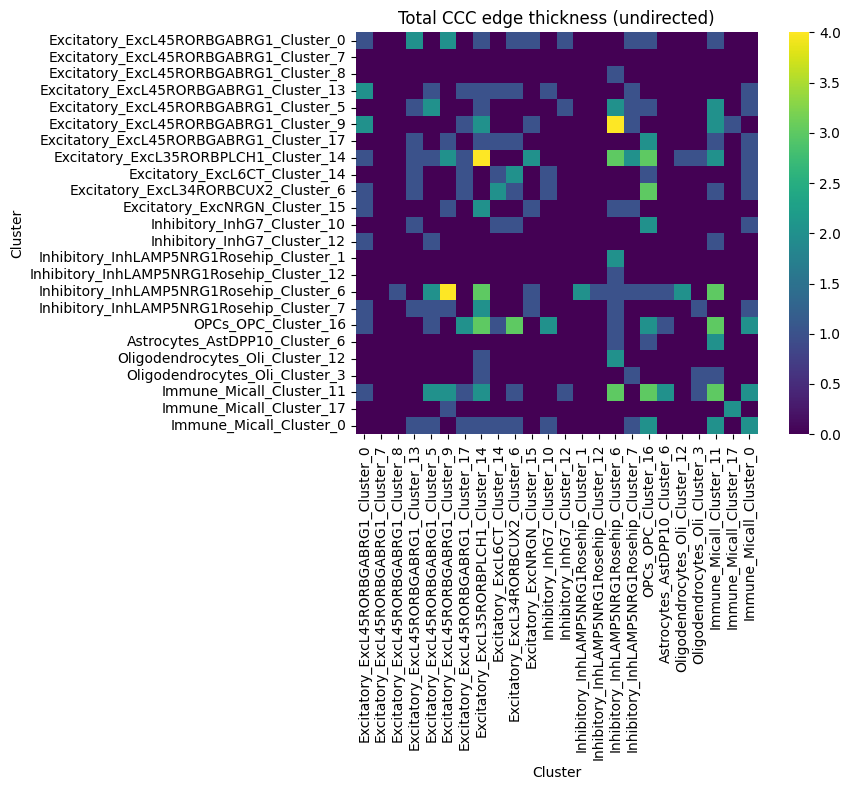

In [12]:
mat_thick = pd.DataFrame(true_total_undir, index=cluster_order, columns=cluster_order)
plt.figure(figsize=(10, 8))
sns.heatmap(mat_thick, cmap="viridis", square=True)
plt.title("Total CCC edge thickness (undirected)")
plt.xlabel("Cluster")
plt.ylabel("Cluster")
plt.tight_layout()
plt.savefig(out_dir / "Heatmap_CCCedgethickness_cluster_undirected.pdf", dpi=300)
plt.show()

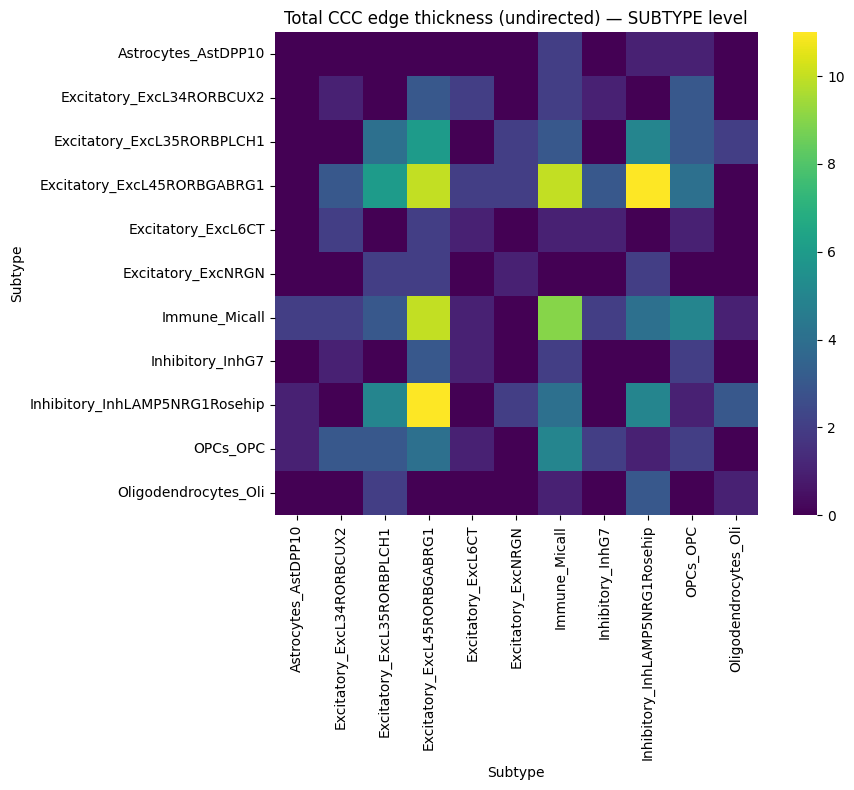

In [13]:
# Heatmap: TRUE total CCC thickness at subtype level

#Get sorted list of unique subtype names
subtypes = sorted(set(df_subtype_stats["subtype_A"]).union(df_subtype_stats["subtype_B"]))

# Initialise subtype x subtype matrix
mat_subtype = pd.DataFrame(0.0, index=subtypes, columns=subtypes)
for (a, b), value in obs_by_subtype.items():
    mat_subtype.loc[a, b] = value
    mat_subtype.loc[b, a] = value

# Plot 
plt.figure(figsize=(10, 8))
sns.heatmap(mat_subtype, cmap="viridis", square=True)
plt.title("Total CCC edge thickness (undirected) — SUBTYPE level")
plt.xlabel("Subtype")
plt.ylabel("Subtype")
plt.tight_layout()
plt.savefig(out_dir / "Heatmap_CCCedgethickness_subtype_undirected.pdf", dpi=300)
plt.show()

## CCC plots

In [14]:
significant_subtype_edges

{('Excitatory_ExcL34RORBCUX2', 'Excitatory_ExcL6CT'),
 ('Excitatory_ExcL34RORBCUX2', 'OPCs_OPC'),
 ('Excitatory_ExcL35RORBPLCH1', 'Excitatory_ExcL35RORBPLCH1'),
 ('Excitatory_ExcL35RORBPLCH1', 'Excitatory_ExcL45RORBGABRG1'),
 ('Excitatory_ExcL35RORBPLCH1', 'Excitatory_ExcNRGN'),
 ('Excitatory_ExcL35RORBPLCH1', 'OPCs_OPC'),
 ('Excitatory_ExcL45RORBGABRG1', 'Excitatory_ExcL45RORBGABRG1'),
 ('Excitatory_ExcL45RORBGABRG1', 'OPCs_OPC'),
 ('Immune_Micall', 'OPCs_OPC'),
 ('Inhibitory_InhG7', 'OPCs_OPC'),
 ('OPCs_OPC', 'OPCs_OPC')}

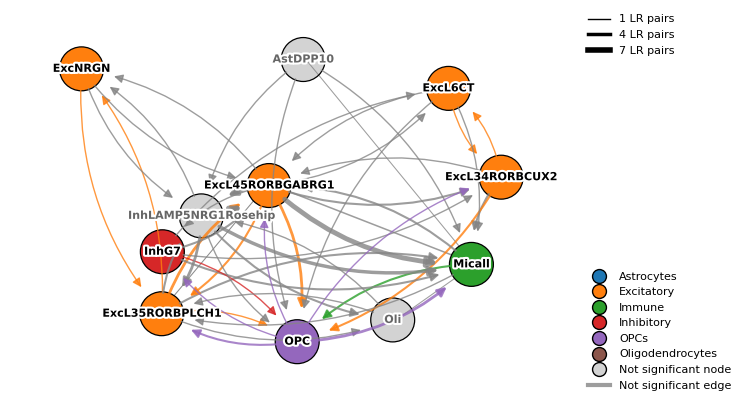

In [15]:
figpath = out_dir / "CCCedgesnull_Set309_subtype_nx.pdf"
fig = CCC.plot_ccc_subtypenetwork_sig_grey(true_pairs,
                                       sig_pairs=significant_subtype_edges, 
                                       minlr=1,mincnt=1,
                                       savepath=figpath, 
                                       nodefonts=8, 
                                       legendfont=8,
                                       figsize=(9,5),
                                       width_max=4,
                                       arrow_size=13)

In [17]:
#comp_loads = pd.read_csv("/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/_set_data/PLSX_loadings_bsrx_NORMALinv.csv")
comp_loads = pd.read_csv('C:/Users/gabri/Documents/Data_projects/MCcharactertization/ROSMAP/Top_sets/Set309/_set_data/PLSX_loadings_bsrx_NORMALinv.csv')


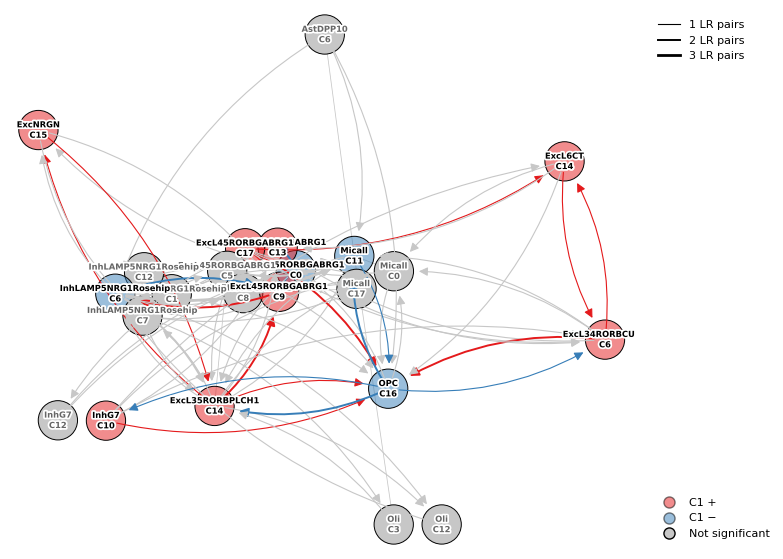

In [18]:
figpath = out_dir / "CCCedgesnull_Set309_cluster_nx.pdf"

fig, ax = CCC.plot_ccc_cluster_network_sig_grey(
    true_pairs,
    title="",
    sig_pairs=significant_AGM_edges,
    pls_df=comp_loads,
    pls_component=1,
    minlr=1,
    mincnt=1,
    node_size=800,
    label_fontsize=6,
    legendfont=8,
    width_max=2,
    arrow_size=13,
    figsize=(10, 7),
    savepath=figpath,
    r_base=0.051,
    spring_k=20,
)

In [19]:
tp = true_pairs_annotated.copy()
tp["sender_subtype"] = tp["sender_cluster"].map(cluster_to_subtype)
tp["receiver_subtype"] = tp["receiver_cluster"].map(cluster_to_subtype)

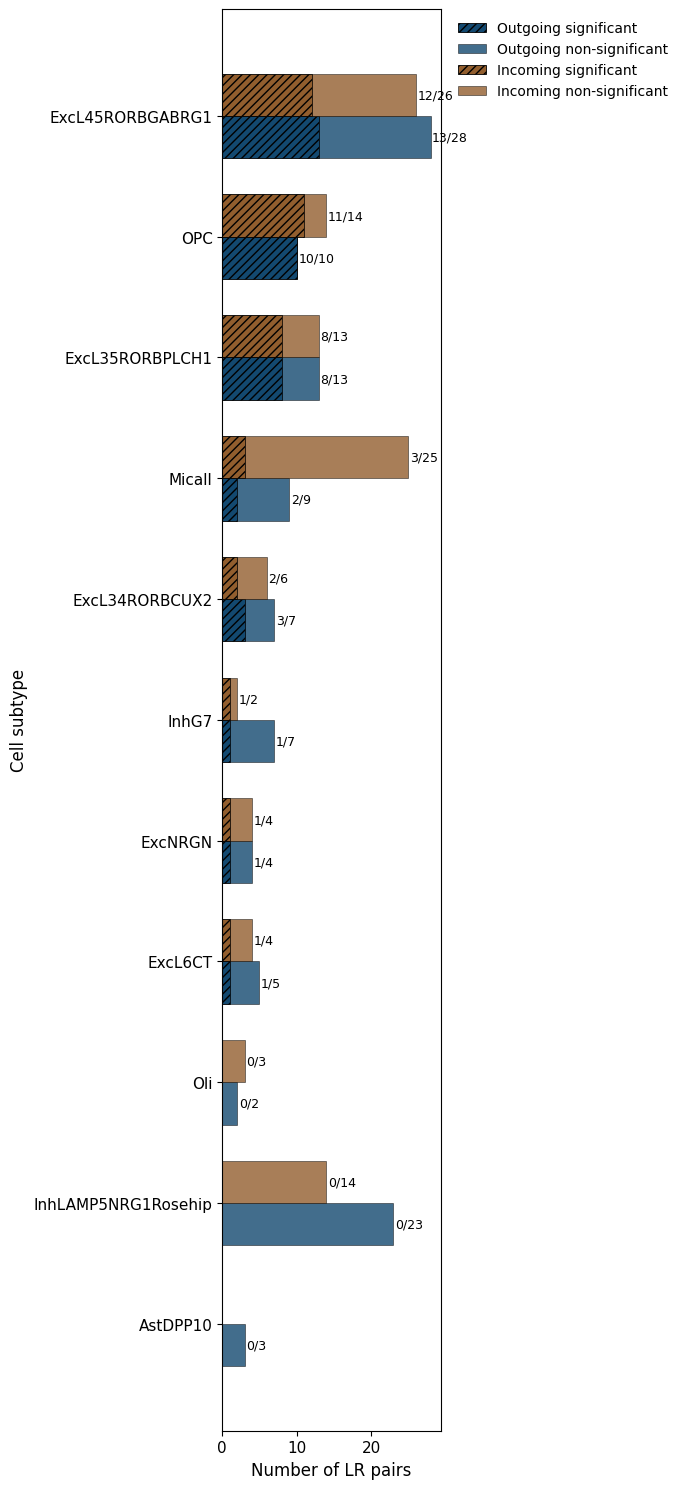

In [20]:
# Count LR interactions sent and received by each subtype, and how many are significant
lr = tp[tp["directionality"] == "Ligand-Receptor"]
subtypes = sorted(set(tp["sender_subtype"]) | set(tp["receiver_subtype"]))

rows = []
for sub in subtypes:
    sent = lr[lr["sender_subtype"] == sub]
    received = lr[lr["receiver_subtype"] == sub]
    rows.append({
        "subtype": sub,
        "out_total": len(sent),
        "out_sig": sent["significant_subtype_edge"].sum(),
        "in_total": len(received),
        "in_sig": received["significant_subtype_edge"].sum(),
    })

lr_summary = pd.DataFrame(rows)
lr_summary["total_sig"] = lr_summary["out_sig"] + lr_summary["in_sig"]
lr_summary["label"] = lr_summary["subtype"].map(CCC.subtype_label)
lr_summary = lr_summary.sort_values("total_sig").reset_index(drop=True)


# Plot: one outgoing and one incoming bar per subtype, significant part hatched
bar_h = 0.35
y = np.arange(len(lr_summary))

def stacked_bar(y_pos, sig, total, colour, name):
    """One set of bars: hatched significant part, then the non-significant rest."""
    plt.barh(y_pos, sig, height=bar_h, color=colour, edgecolor="black",
             hatch="////", linewidth=0.6, label=f"{name} significant")
    plt.barh(y_pos, total - sig, left=sig, height=bar_h, color=colour, alpha=0.8,
             edgecolor="black", linewidth=0.4, label=f"{name} non-significant")

    # "significant/total" label at the end of each bar
    for yi, s, t in zip(y_pos, sig, total):
        if t > 0:
            plt.text(t + 0.2, yi, f"{s}/{t}", va="center", fontsize=9)

plt.figure(figsize=(7, 15))
stacked_bar(y - bar_h / 2, lr_summary["out_sig"], lr_summary["out_total"], "#134970", "Outgoing")
stacked_bar(y + bar_h / 2, lr_summary["in_sig"], lr_summary["in_total"], "#925e2e", "Incoming")

plt.yticks(y, lr_summary["label"], fontsize=11)
plt.xticks(fontsize=11)
plt.xlabel("Number of LR pairs", fontsize=12)
plt.ylabel("Cell subtype", fontsize=12)
plt.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)

plt.tight_layout()
plt.savefig(out_dir / "CCCedgesnull_Set309_subtype_LR_summary.pdf", dpi=300,
            bbox_inches="tight", pad_inches=0.5, transparent=True)
plt.show()